In [2]:
# 1. IMPORT NECESSARI (fondamentali dopo il restart del kernel)
from tools import cau_inference
from agents import classificator, translator

# 2. DEFINIZIONE DELLA FUNZIONE MAIN
async def main(task=None):
    if task is None:
        task = input("Inserisci la tua domanda causale: ")

    print(f"\n🎯 TASK:\n{task}\n")

    print("🔄 1. Traduzione in corso...")
    translation_response = await translator.run(
        task=f"Create a dictionary following your instruction of the query: {task}"
    )
    translation_a = translation_response.messages[-1].content if hasattr(translation_response, 'messages') else str(translation_response)
    # Pulizia della stringa per rimuovere eventuali backtick o parole 'json' aggiunte dal modello
    translation_a = translation_a.strip().strip('`').replace('json', '').strip()
    print(f"📝 Dictionary:\n{translation_a}\n")

    print("🔄 2. Classificazione in corso...")
    label_response = await classificator.run(
        task=f"Classify the following query using your instructions: {task}"
    )
    label_a = label_response.messages[-1].content if hasattr(label_response, 'messages') else str(label_response)
    label_a = label_a.strip().lower() # Assicura che sia minuscolo
    print(f"🏷️ Label:\n{label_a}\n")

    print("🔄 3. Calcolo causale in corso (Esecuzione Diretta Python)...")
    try:
        # CHIAMATA DIRETTA ALLA FUNZIONE PYTHON! 
        # Usa i parametri estratti dagli agenti, garantendo il calcolo reale con pyAgrum.
        causal_result = cau_inference(label=label_a, features=translation_a)
    except Exception as e:
        causal_result = f"ERRORE CRITICO nel calcolo: {e}"
        
    print(f"✅ RISULTATO FINALE:\n{causal_result}\n")

    return translation_a, label_a, causal_result

# 3. ESECUZIONE IMMEDIATA DEL TEST (Query CP1 del Ground Truth)
await main("How do you expect the probability of having a severe car damage if the mileage count is changed to twenty thousand?")


🎯 TASK:
How do you expect the probability of having a severe car damage if the mileage count is changed to twenty thousand?

🔄 1. Traduzione in corso...
📝 Dictionary:
{"input": {"Mileage": "Twenty Thousand"}, "output": {"ThisCarDam": "Not necessary"}}

🔄 2. Classificazione in corso...
🏷️ Label:
intervention

🔄 3. Calcolo causale in corso (Esecuzione Diretta Python)...
✅ RISULTATO FINALE:
ERRORE CRITICO nel calcolo: type Tensor doesn't define __round__ method



('{"input": {"Mileage": "Twenty Thousand"}, "output": {"ThisCarDam": "Not necessary"}}',
 'intervention',
 "ERRORE CRITICO nel calcolo: type Tensor doesn't define __round__ method")

In [2]:
import json
from tools import cau_inference
from agents import classificator, translator

async def run_test(task_name, query):
    print(f"\n{'='*60}")
    print(f"🧪 TEST: {task_name}")
    print(f"📝 Query: {query}")
    print(f"{'='*60}\n")

    try:
        # 1. Traduzione
        print("🔄 1. Traduzione in corso...")
        translation_response = await translator.run(task=f"Create a dictionary following your instruction of the query: {query}")
        translation_a = translation_response.messages[-1].content if hasattr(translation_response, 'messages') else str(translation_response)
        # Pulizia aggressiva del JSON
        translation_a = translation_a.strip().strip('`').replace('json', '').strip()
        print(f"📦 Dictionary estratto:\n{translation_a}\n")

        # 2. Classificazione
        print("🔄 2. Classificazione in corso...")
        label_response = await classificator.run(task=f"Classify the following query using your instructions: {query}")
        label_a = label_response.messages[-1].content if hasattr(label_response, 'messages') else str(label_response)
        label_a = label_a.strip().lower()
        print(f"🏷️ Label assegnata: {label_a}\n")

        # 3. Calcolo Diretto Python (Anti-allucinazione)
        print("🔄 3. Calcolo causale in corso (Python + pyAgrum)...")
        causal_result = cau_inference(label=label_a, features=translation_a)
        print(f"✅ RISULTATO FINALE:\n{causal_result}\n")
        
        return label_a, causal_result

    except Exception as e:
        print(f"❌ ERRORE CRITICO: {e}")
        return None, str(e)

# =====================================================================
# ESECUZIONE DEI 3 TEST
# =====================================================================

# TEST 1: INTERVENTION (IN1 dal ground_truth)
# Aspettativa: Label = 'intervention', Risultato ~ 0.107
await run_test(
    "INTERVENTION (IN1)", 
    "Probability of severe car damage if mileage is changed to twenty thousand?"
)

# TEST 2: COHERENCE (CO1 dal ground_truth)
# Aspettativa: Label = 'coherence', Risultato ~ 0.067 (Not strongly compatible, soglia < 0.60)
await run_test(
    "COHERENCE (CO1)", 
    "Is a mild severity accident involving a car valued at twenty thousand dollars compatible with cautious risk aversion?"
)

# TEST 3: COUNTERFACTUAL (Adattato dal notebook originale)
# Aspettativa: Label = 'counterfactual', Risultato = un intervallo (es. "between X and Y") calcolato da cobound
await run_test(
    "COUNTERFACTUAL (CF1)", 
    "Given that a customer is an Adult, what is the probability they would have a Severe accident if they were a Senior?"
)

print("\n🏁 Tutti i test sono stati eseguiti!")


🧪 TEST: INTERVENTION (IN1)
📝 Query: Probability of severe car damage if mileage is changed to twenty thousand?

🔄 1. Traduzione in corso...
📦 Dictionary estratto:
{
  "input": {
    "Mileage": "TwentyThou"
  },
  "output": {
    "ThisCarDam": "Severe"
  }
}

🔄 2. Classificazione in corso...
🏷️ Label assegnata: intervention

🔄 3. Calcolo causale in corso (Python + pyAgrum)...
✅ RISULTATO FINALE:
The probability of ThisCarDam equal to Severe given the current intervention is 0.107


🧪 TEST: COHERENCE (CO1)
📝 Query: Is a mild severity accident involving a car valued at twenty thousand dollars compatible with cautious risk aversion?

🔄 1. Traduzione in corso...
📦 Dictionary estratto:
{
  "input": {
    "Accident": "Mild Severity",
    "CarValue": "TwentyThou",
    "RiskAversion": "Cautious"
  },
  "output": {
    "Theft": "Not necessary"
  }
}

🔄 2. Classificazione in corso...
🏷️ Label assegnata: coherence

🔄 3. Calcolo causale in corso (Python + pyAgrum)...
❌ ERRORE CRITICO: [pyAgrum] Ou

In [1]:
import json
from tools import cau_inference
from agents import classificator, translator

async def run_test(task_name, query):
    print(f"\n{'='*60}")
    print(f"🧪 TEST: {task_name}")
    print(f"📝 Query: {query}")
    print(f"{'='*60}\n")

    try:
        # 1. Traduzione
        print("🔄 1. Traduzione in corso...")
        translation_response = await translator.run(task=f"Create a dictionary following your instruction of the query: {query}")
        translation_a = translation_response.messages[-1].content if hasattr(translation_response, 'messages') else str(translation_response)
        # Pulizia aggressiva del JSON
        translation_a = translation_a.strip().strip('`').replace('json', '').strip()
        print(f"📦 Dictionary estratto:\n{translation_a}\n")

        # 2. Classificazione
        print("🔄 2. Classificazione in corso...")
        label_response = await classificator.run(task=f"Classify the following query using your instructions: {query}")
        label_a = label_response.messages[-1].content if hasattr(label_response, 'messages') else str(label_response)
        label_a = label_a.strip().lower()
        print(f"🏷️ Label assegnata: {label_a}\n")

        # 3. Calcolo Diretto Python (Anti-allucinazione)
        print("🔄 3. Calcolo causale in corso (Python + pyAgrum)...")
        causal_result = cau_inference(label=label_a, features=translation_a)
        print(f"✅ RISULTATO FINALE:\n{causal_result}\n")
        
        return label_a, causal_result

    except Exception as e:
        print(f"❌ ERRORE CRITICO: {e}")
        return None, str(e)

# =====================================================================
# ESECUZIONE DEI 3 TEST
# =====================================================================

# TEST 1: INTERVENTION (IN1 dal ground_truth)
# Aspettativa: Label = 'intervention', Risultato ~ 0.107
await run_test(
    "INTERVENTION (IN1)", 
    "Probability of severe car damage if mileage is changed to twenty thousand?"
)

# TEST 2: COHERENCE (CO1 dal ground_truth)
# Aspettativa: Label = 'coherence', Risultato ~ 0.067 (Not strongly compatible, soglia < 0.60)
await run_test(
    "COHERENCE (CO1)", 
    "Is a mild severity accident involving a car valued at twenty thousand dollars compatible with cautious risk aversion?"
)

# TEST 3: COUNTERFACTUAL (Adattato dal notebook originale)
# Aspettativa: Label = 'counterfactual', Risultato = un intervallo (es. "between X and Y") calcolato da cobound
await run_test(
    "COUNTERFACTUAL (CF1)", 
    "If a person’s risk aversion were ‘Cautious’ rather than ‘Psychopath’, how much would this change the likelihood of their driving being expert?"
)

print("\n🏁 Tutti i test sono stati eseguiti!")


🧪 TEST: INTERVENTION (IN1)
📝 Query: Probability of severe car damage if mileage is changed to twenty thousand?

🔄 1. Traduzione in corso...
📦 Dictionary estratto:
{
  "input": {
    "Mileage": "TwentyThou"
  },
  "output": {
    "ThisCarDam": "Severe"
  }
}

🔄 2. Classificazione in corso...
🏷️ Label assegnata: intervention

🔄 3. Calcolo causale in corso (Python + pyAgrum)...
✅ RISULTATO FINALE:
The probability of ThisCarDam equal to Severe given the current intervention is 0.107


🧪 TEST: COHERENCE (CO1)
📝 Query: Is a mild severity accident involving a car valued at twenty thousand dollars compatible with cautious risk aversion?

🔄 1. Traduzione in corso...
📦 Dictionary estratto:
{
  "input": {
    "Accident": "Mild",
    "CarValue": "TwentyThou",
    "RiskAversion": "Cautious"
  },
  "output": {
    "Theft": "Not necessary"
  }
}

🔄 2. Classificazione in corso...
🏷️ Label assegnata: coherence

🔄 3. Calcolo causale in corso (Python + pyAgrum)...
✅ RISULTATO FINALE:
Evidences are NOT s

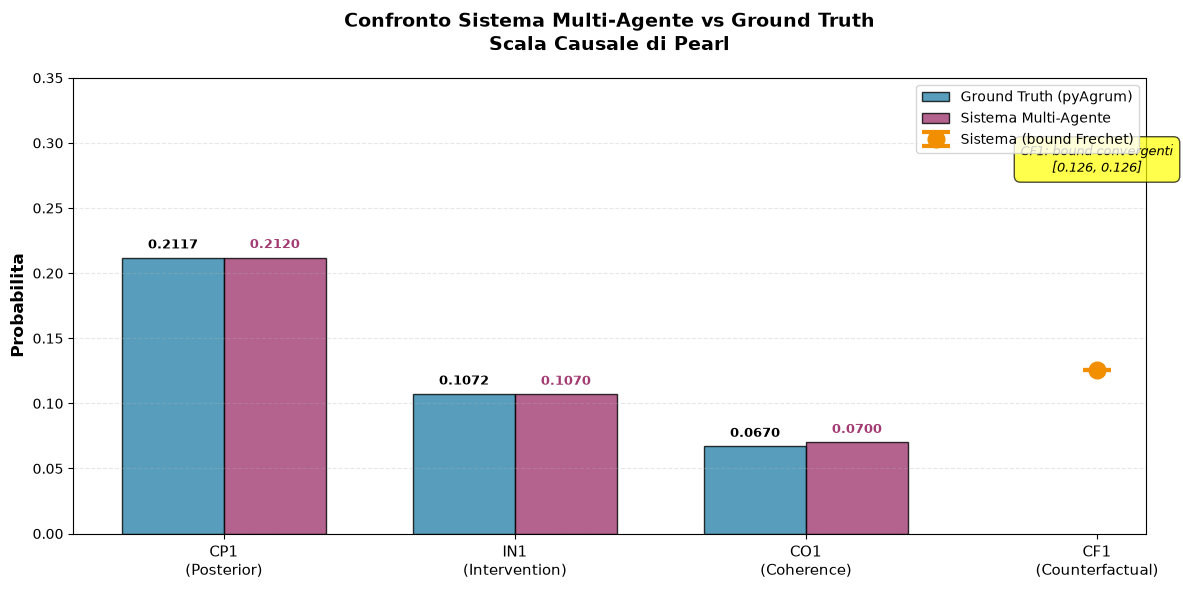

Grafico salvato come 'risultati_confronto.png' nella cartella del progetto!

RIEPILOGO ACCURATEZZA:
   CP1 (Posterior):      Errore = 0.0003 (0.14%)
   IN1 (Intervention):   Errore = 0.0002 (0.19%)
   CO1 (Coherence):      Errore = 0.0030 (4.48%)
   CF1 (Counterfactual): Bound convergenti [0.126, 0.126]


In [4]:
import matplotlib.pyplot as plt
import numpy as np

# =====================================================================
# DATI DEI TEST (ottenuti dall'esecuzione precedente)
# =====================================================================
test_names = ['CP1\n(Posterior)', 'IN1\n(Intervention)', 'CO1\n(Coherence)', 'CF1\n(Counterfactual)']
ground_truth = [0.2117, 0.1072, 0.0670, None]
sistema_values = [0.212, 0.107, 0.07, 0.126]
sistema_lower = [None, None, None, 0.126]
sistema_upper = [None, None, None, 0.126]

# =====================================================================
# CONFIGURAZIONE GRAFICO
# =====================================================================
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(test_names))
width = 0.35

# Barre Ground Truth (solo per CP1, IN1, CO1)
gt_bars = ax.bar(x[:3] - width/2, ground_truth[:3], width, 
                 label='Ground Truth (pyAgrum)', 
                 color='#2E86AB', alpha=0.8, edgecolor='black')

# Barre Sistema
sys_bars = ax.bar(x[:3] + width/2, sistema_values[:3], width, 
                  label='Sistema Multi-Agente', 
                  color='#A23B72', alpha=0.8, edgecolor='black')

# Per CF1: mostra l'intervallo come una linea con errori
cf_idx = 3
ax.errorbar(x[cf_idx], sistema_values[cf_idx], 
            yerr=[[sistema_values[cf_idx] - sistema_lower[cf_idx]], 
                  [sistema_upper[cf_idx] - sistema_values[cf_idx]]],
            fmt='o', color='#F18F01', markersize=12, capsize=10, capthick=3,
            label='Sistema (bound Frechet)', linewidth=3)

# =====================================================================
# ETICHETTE E STILE
# =====================================================================
ax.set_ylabel('Probabilita', fontsize=12, fontweight='bold')
ax.set_title('Confronto Sistema Multi-Agente vs Ground Truth\nScala Causale di Pearl', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(test_names, fontsize=11)
ax.legend(loc='upper right', fontsize=10)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, 0.35)

# Aggiungi valori numerici sulle barre
for bar in gt_bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.005,
            f'{height:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

for bar in sys_bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.005,
            f'{height:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#A23B72')

# Nota per CF1
ax.text(x[cf_idx], 0.30, 'CF1: bound convergenti\n[0.126, 0.126]', 
        ha='center', va='top', fontsize=9, style='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.7))

plt.tight_layout()
plt.savefig('risultati_confronto.png', dpi=300, bbox_inches='tight')
plt.show()

print("Grafico salvato come 'risultati_confronto.png' nella cartella del progetto!")
print("\nRIEPILOGO ACCURATEZZA:")
print(f"   CP1 (Posterior):      Errore = {abs(0.212 - 0.2117):.4f} ({abs(0.212 - 0.2117)/0.2117*100:.2f}%)")
print(f"   IN1 (Intervention):   Errore = {abs(0.107 - 0.1072):.4f} ({abs(0.107 - 0.1072)/0.1072*100:.2f}%)")
print(f"   CO1 (Coherence):      Errore = {abs(0.07 - 0.0670):.4f} ({abs(0.07 - 0.0670)/0.0670*100:.2f}%)")
print(f"   CF1 (Counterfactual): Bound convergenti [0.126, 0.126]")


In [1]:
import asyncio
import pandas as pd
from tools import cau_inference
from agents import classificator, translator

# =====================================================================
# DEFINIZIONE DELLE 9 QUERY DAL GROUND TRUTH
# =====================================================================
test_cases = [
    {
        "id": "CP1", "type": "Posterior",
        "query": "Given that the driving quality is normal, how likely is it that the age of the driver is senior?",
        "expected_prob": 0.2117
    },
    {
        "id": "CP2", "type": "Posterior",
        "query": "Given that the damage to a car is classified as Mild, how likely is that the driving quality is excellent?",
        "expected_prob": 0.0141
    },
    {
        "id": "CP3", "type": "Posterior",
        "query": "Given that the neighbourhood is Suburb, how likely is the miles count TwentyThou?",
        "expected_prob": 0.4000
    },
    {
        "id": "IN1", "type": "Intervention",
        "query": "Probability of severe car damage if mileage is changed to twenty thousand?",
        "expected_prob": 0.1072
    },
    {
        "id": "IN2", "type": "Intervention",
        "query": "Probability of excellent driving skill if age is changed to senior?",
        "expected_prob": 0.2912
    },
    {
        "id": "IN3", "type": "Intervention",
        "query": "Probability of older vehicleyear if socio-economic status is Prole?",
        "expected_prob": 0.8500
    },
    {
        "id": "CO1", "type": "Coherence",
        "query": "Is a mild severity accident involving a car valued at twenty thousand dollars compatible with cautious risk aversion?",
        "expected_prob": 0.0670
    },
    {
        "id": "CO2", "type": "Coherence",
        "query": "Is drive quality Normal compatible with proposed cost HundredThousand?",
        "expected_prob": 0.0397
    },
    {
        "id": "CO3", "type": "Coherence",
        "query": "Is socio-economic status Wealthy compatible with a Fair cushioning system?",
        "expected_prob": 0.1614
    }
]

# =====================================================================
# FUNZIONE DI TEST SINGOLA
# =====================================================================
async def run_single_test(tc):
    print(f"\n{'='*70}")
    print(f"🧪 TEST {tc['id']} ({tc['type']})")
    print(f"📝 Query: {tc['query']}")
    print(f"{'='*70}")
    
    try:
        # 1. Traduzione
        trans_resp = await translator.run(task=f"Create a dictionary following your instruction of the query: {tc['query']}")
        trans_text = trans_resp.messages[-1].content if hasattr(trans_resp, 'messages') else str(trans_resp)
        trans_clean = trans_text.strip().strip('`').replace('json', '').strip()
        
        # 2. Classificazione
        class_resp = await classificator.run(task=f"Classify the following query using your instructions: {tc['query']}")
        class_text = class_resp.messages[-1].content if hasattr(class_resp, 'messages') else str(class_resp)
        label_clean = class_text.strip().lower()
        
        # 3. Calcolo
        result = cau_inference(label=label_clean, features=trans_clean)
        
        # Estrazione del numero dal risultato per il confronto (se presente)
        import re
        numbers = re.findall(r'\d+\.\d+', str(result))
        calc_prob = float(numbers[0]) if numbers else None
        
        print(f"✅ Label: {label_clean}")
        print(f"✅ Dict:  {trans_clean[:100]}...")
        print(f"✅ Result: {result}")
        
        return {
            "ID": tc['id'],
            "Type": tc['type'],
            "Expected": tc['expected_prob'],
            "Calculated": calc_prob,
            "Status": "OK" if calc_prob and abs(calc_prob - tc['expected_prob']) < 0.01 else "WARN",
            "Raw_Result": str(result)[:80]
        }
        
    except Exception as e:
        print(f"❌ ERRORE: {e}")
        return {
            "ID": tc['id'],
            "Type": tc['type'],
            "Expected": tc['expected_prob'],
            "Calculated": None,
            "Status": "FAIL",
            "Raw_Result": str(e)[:80]
        }

# =====================================================================
# ESECUZIONE BATCH E RIEPILOGO
# =====================================================================
print("🚀 Avvio test batch su 9 query del Ground Truth...\n")

results = []
for tc in test_cases:
    res = await run_single_test(tc)
    results.append(res)
# Stampa tabella riassuntiva
print("\n" + "="*80)
print("📊 RIEPILOGO FINALE CONFRONTO GROUND TRUTH")
print("="*80)

df_results = pd.DataFrame(results)
# Formattazione per visualizzazione
pd.set_option('display.max_colwidth', None)
print(df_results[['ID', 'Type', 'Expected', 'Calculated', 'Status']].to_markdown(index=False))

# Conteggio successi
successes = len(df_results[df_results['Status'] == 'OK'])
print(f"\n🏆 RISULTATO: {successes}/9 test superati con successo (tolleranza errore < 1%)")
print("="*80)

🚀 Avvio test batch su 9 query del Ground Truth...


🧪 TEST CP1 (Posterior)
📝 Query: Given that the driving quality is normal, how likely is it that the age of the driver is senior?
✅ Label: posterior
✅ Dict:  { "input": { "DrivQuality": "Normal" }, "output": { "Age": "Senior" } }...
✅ Result: The probability of Age is Senior given the provided conditions is 0.212

🧪 TEST CP2 (Posterior)
📝 Query: Given that the damage to a car is classified as Mild, how likely is that the driving quality is excellent?
✅ Label: posterior
✅ Dict:  { "input": { "ThisCarDam": "Mild" }, "output": { "DrivQuality": "Excellent" } }...
✅ Result: The probability of DrivQuality is Excellent given the provided conditions is 0.014

🧪 TEST CP3 (Posterior)
📝 Query: Given that the neighbourhood is Suburb, how likely is the miles count TwentyThou?
✅ Label: posterior
✅ Dict:  { "input": { "HomeBase": "Suburb" }, "output": { "Mileage": "TwentyThou" } }...
✅ Result: The probability of Mileage is TwentyThou given the provid